# Seleção de features (Fase 3)

**Objetivo:** decidir quais colunas da camada Gold `features_aluno` entram no modelo
supervisionado, como cada uma deve ser tratada no pré-processamento, e registrar
o motivo de cada decisão.

**Entrada:** `data/sample/features_aluno` (1 linha por aluno avaliado em 2024).
**Saída:** a lista final de features, usada pelo notebook `03_modelagem_supervisionada`.


## 1. Bibliotecas e configuracões

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)

In [26]:
CAMINHO_GOLD = "../data/sample/features_aluno"

df = pd.read_parquet(CAMINHO_GOLD)
df.shape

(1610754, 35)

## 2. Raio-x das colunas

Tipo, número de valores distintos e percentual de nulos de cada coluna.
É a base para separar alvo, identificadores, constantes e features.

In [27]:
raio_x = pd.DataFrame({
    "tipo": df.dtypes,
    "valores_distintos": df.nunique(),
    "pct_nulos": (df.isna().mean() * 100).round(3),
}).sort_values("valores_distintos")

raio_x

,tipo,valores_distintos,pct_nulos
ano,int32,1,0.000
rede_codigo,str,1,0.000
uf_anomala,bool,2,0.000
alfabetizado,bool,2,0.000
mun_elegivel_meta,object,2,0.001
regiao,str,5,0.000
caderno,str,22,0.000
sigla_uf,str,25,0.000
mun_idade_mediana,float64,35,0.000
mun_total_escolas,int32,134,0.000


In [28]:
# valores das colunas constantes
df[["ano", "rede_codigo"]].drop_duplicates()


,ano,rede_codigo
0,2024,3


In [29]:
#avaliando a variável "caderno"
df.groupby("caderno")["alfabetizado"].agg(["mean", "count"]).sort_values("count")

,mean,count
caderno,,
43,0.454545,11
14,0.598534,74081
19,0.592374,74274
13,0.600269,74330
9,0.591909,74334
21,0.595269,74368
17,0.589278,74369
11,0.594284,74382
18,0.583775,74402


In [30]:
# avaliando a coluna"uf_anomala"
pd.crosstab(df["uf_anomala"], df["sigla_uf"] == "RS")

sigla_uf,False,True
uf_anomala,,
False,1549701,0
True,0,61053


**Conclusões do raio-x:**

- **Variáveis Constantes:** `ano` (sempre 2024) e `rede_codigo` (sempre "3") têm um único valor
  em todas as linhas, portanto não carregam informação para o modelo e serão excluídas.

- **Variáveis Binárias:** `alfabetizado` é uma variável binária e é justamente o **alvo**
  do modelo. `uf_anomala` e `mun_elegivel_meta` são candidatas a feature. A
  `mun_elegivel_meta` tem tipo `object` por causa de 0,001% de nulos e precisará de
  imputação.

- **Variáveis Categóricas de baixa cardinalidade:** `regiao` (5), `sigla_uf` (25) e
  `caderno` (22) são texto. `regiao` e `sigla_uf` precisarão de encoding; o `caderno`
  é avaliado abaixo.
 
- **Identificadores:** `id_aluno` tem um valor por linha (chave única); `id_escola` (36.920)
  e `id_municipio` (5.450) identificam grupos. Nenhum entra como feature. 
  O `id_municipio` será usado para separar treino e teste.

- **Colunas municipais:** `mun_pib_per_capita` tem exatamente 5.450 valores, um por município.

- **Nulos:** `mun_distancia_meta_anterior` e `mun_meta_ano_alvo` (2,6%, mesmo percentual,
  provavelmente as mesmas linhas), `mun_taxa_ano_anterior` (0,5%), as quatro
  `mun_pct_va_*` (0,006%) e `mun_elegivel_meta` (0,001%). 
  Com todos abaixo de 3% as colunas serão mantidas e os vazios serão tratados por imputação.

- **`caderno`:** nos 21 cadernos com 74 mil a 84 mil alunos, a taxa de alfabetização
  varia apenas entre 58,4% e 60,1%. O caderno 43 tem só 11 alunos. Descartado na seção 5.
  
- **`uf_anomala`:** marca exatamente os 61.053 alunos do RS e nenhum fora dele, ou seja,
  repete a informação de `sigla_uf`. Descartada na seção 5.


## 3. O alvo: `alfabetizado`

**Definição:** o aluno é considerado alfabetizado quando sua proficiência no Saeb é
maior ou igual a 743 pontos (ponto de corte do Indicador Criança Alfabetizada).
Fonte: README do projeto, seção 3 (a regra foi verificada na Silver da Fase 2).

In [31]:
contagem = df["alfabetizado"].value_counts()
percentual = df["alfabetizado"].value_counts(normalize=True).mul(100).round(1)

pd.DataFrame({"alunos": contagem, "percentual": percentual})

,alunos,percentual
alfabetizado,,
True,956343,59.4
False,654411,40.6


**Decisão: inverter o alvo**

No scikit-learn, precisão, recall e F1 são calculados em relação à **classe positiva**,
que por padrão é a classe 1. Na base, o 1 (`True`) é o aluno **alfabetizado**. Treinado
assim, o recall responderia "de todas as crianças alfabetizadas, quantas o modelo
encontrou?", e não é essa a pergunta da secretaria de educação.

O objetivo é **encontrar as crianças em risco**. O erro mais grave é o falso negativo:
uma criança não alfabetizada que o modelo classifica como alfabetizada e que, por isso,
fica fora da ação da política pública.

Por isso o alvo é invertido: **1 = não alfabetizado (risco)** e **0 = alfabetizado**.
A acurácia não é afetada pela inversão; precisão, recall e F1 passam a medir a
capacidade do modelo de encontrar a classe de risco.

In [32]:
# alvo invertido: 1 = não alfabetizado (classe de risco), 0 = alfabetizado
y = (~df["alfabetizado"]).astype(int).rename("nao_alfabetizado")

# prova da inversão: cruza o alvo original com o novo
pd.crosstab(df["alfabetizado"], y, margins=True)

nao_alfabetizado,0,1,All
alfabetizado,,,
False,0,654411,654411
True,956343,0,956343
All,956343,654411,1610754


In [33]:
rotulos = {0: "alfabetizado", 1: "não alfabetizado (risco)"}
y.value_counts().rename(index=rotulos)

nao_alfabetizado
alfabetizado                956343
não alfabetizado (risco)    654411
Name: count, dtype: int64

**Conclusões sobre o alvo:**

- **Balanceamento:** 59,4% dos alunos são alfabetizados e 40,6% não alfabetizados.
  A base é relativamente balanceada, portanto não são necessárias técnicas de balanceamento
  artificial, mas a divisão entre treino e teste deve preservar essa proporção.
- **Baseline ingênuo:** um modelo que responde sempre "alfabetizado" acerta 59,4%
  (acurácia), mas não identifica nenhuma criança em risco (recall de 0% na classe 1).
  O modelo final precisa superar esse patamar, e a acurácia sozinha não basta para
  avaliá-lo.
- **Métrica prioritária:** o erro mais grave é o falso negativo, a criança em risco
  que o modelo classifica como alfabetizada e que fica fora da política pública.
  Por isso a métrica prioritária é o **recall da classe de risco**, acompanhado da
  **precisão** e do **F1**: um modelo que apontasse risco para todos teria recall de
  100% e nenhuma utilidade prática.

## 4. Redundância entre as features

Verifica se alguma coluna numérica municipal repete a informação de outra
(multicolinearidade). A redundância prejudica pouco a previsão, mas distorce a
interpretação (Feature Importance e SHAP), porque o modelo divide a importância
entre colunas que dizem o mesmo.

As correlações são calculadas com **uma linha por município**: as colunas `mun_` se
repetem em todos os alunos do município, e usar os 1,6 milhão de alunos daria a
municípios grandes um peso desproporcional.

In [34]:
municipios = df.drop_duplicates(subset="id_municipio")
numericas_mun = [c for c in df.columns if c.startswith("mun_") and c != "mun_elegivel_meta"]

print(f"Municípios: {len(municipios)} | colunas numéricas municipais: {len(numericas_mun)}")

Municípios: 5450 | colunas numéricas municipais: 23


In [35]:
# teste da conta exata: distância = taxa do ano anterior - meta
diferenca = (
    municipios["mun_taxa_ano_anterior"]
    - municipios["mun_meta_ano_alvo"]
    - municipios["mun_distancia_meta_anterior"]
)
diferenca.abs().max()

np.float64(0.0)

In [36]:
# pares de colunas mais correlacionados (valor absoluto)
corr = municipios[numericas_mun].corr().abs()

pares = (
    corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
        .stack()
        .sort_values(ascending=False)
)
pares.head(10)

mun_taxa_ano_anterior          mun_meta_ano_alvo                   0.978675
mun_idade_mediana              mun_indice_envelhecimento           0.927986
mun_taxa_ano_anterior          mun_distancia_meta_anterior         0.847766
mun_moradores_por_domicilio    mun_idade_mediana                   0.806024
mun_alunos_por_docente         mun_alunos_por_turma                0.733688
mun_taxa_alfabetizacao_adulta  mun_pct_va_administracao_publica    0.732840
mun_meta_ano_alvo              mun_distancia_meta_anterior         0.720743
mun_total_escolas              mun_populacao                       0.691818
mun_pct_rural                  mun_pct_transporte                  0.652632
mun_moradores_por_domicilio    mun_indice_envelhecimento           0.642833
dtype: float64

**Critério (definido antes da análise):**

| Relação | Decisão |
|---|---|
| Conta exata ou correlação acima de 0,9 | Manter só uma das colunas |
| Correlação entre 0,7 e 0,9 | Manter as duas e considerar a relação na interpretação |
| Correlação abaixo de 0,7 | Nada a fazer |

**Resultados:**

- `mun_meta_ano_alvo` tem correlação de 0,98 com `mun_taxa_ano_anterior` e pode ser
  calculada exatamente a partir das outras duas colunas de meta (diferença máxima 0).
  **Será removida**; ficam a taxa do ano anterior (onde o município estava) e a
  distância da meta (quanto faltava, medida de pressão institucional segundo o README).
- `mun_idade_mediana` tem correlação de 0,93 com `mun_indice_envelhecimento` e de 0,81
  com `mun_moradores_por_domicilio`. **Será removida**: resolve as duas relações, e tem
  só 35 valores distintos, contra 4.105 do índice de envelhecimento.
- Relações moderadas mantidas (cuidado na interpretação do SHAP):
  `mun_alunos_por_docente` × `mun_alunos_por_turma` (0,73) e
  `mun_taxa_alfabetizacao_adulta` × `mun_pct_va_administracao_publica` (0,73).

**Observação metodológica:** a correlação compara duas colunas por vez e não detecta
uma coluna que é combinação de várias. `mun_distancia_meta_anterior` tem correlação de
0,85 com a taxa e 0,72 com a meta, nenhuma próxima de 1, mas é exatamente a diferença
entre as duas. Por isso foi necessário o teste da conta exata.

## 5. Colunas excluídas do modelo

| Coluna | Grupo | Motivo | Evidência |
|---|---|---|---|
| `alfabetizado` | Alvo | É a variável que o modelo prevê. Sai das features e vira o `y`, invertido (1 = risco). | Seção 3 |
| `id_aluno` | Identificador | Identifica cada aluno (um valor por linha). Não carrega informação que se generalize para alunos novos. | Seção 2 (raio-x) |
| `id_escola` | Identificador | Identifica a escola. É um rótulo sem significado próprio, com 36.920 valores. | Seção 2 (raio-x) |
| `id_municipio` | Identificador | Identifica o município. Não entra como feature, mas é usado para dividir treino e teste por município (`COLUNA_GRUPO`). | Seção 2 (raio-x) |
| `ano` | Constante | Tem o mesmo valor em todas as linhas. Sem variação, não carrega informação. | Seção 2 (raio-x) |
| `rede_codigo` | Constante | Tem o mesmo valor em todas as linhas. Sem variação, não carrega informação. | Seção 2 (raio-x) |
| `peso_aluno` | Peso amostral | Indica quantos alunos da população cada avaliado representa. Descreve o desenho da avaliação, não a criança nem o seu contexto. Pode ser usado como peso no treino (`sample_weight`), decisão do notebook 03. | README, seção 3; correlação no `01_eda`, seção 7 |
| `caderno` | Descartada na seleção | Não está disponível no momento da previsão: o caderno só é sorteado no dia da prova, e o modelo deve sinalizar o risco antes dela. Além disso, os cadernos são desenhados para ter dificuldade equivalente, e os dados confirmam: a taxa de alfabetização quase não varia entre cadernos entre 74 mil e 84 mil alunos cada (o caderno 43, com 11 alunos, é exceção sem relevância estatística). | Seção 2 (raio-x)|
| `uf_anomala` | Descartada na seleção | Redundante com `sigla_uf`: marca exatamente os 61.053 alunos do RS, e nenhum fora dele. Após o encoding, `sigla_uf_RS` carrega a mesma informação. A exclusão não remove o RS da base. | Seção 2 (cruzamento com `sigla_uf`) |
| `mun_meta_ano_alvo` | Redundante | Correlação de 0,98 com `mun_taxa_ano_anterior`; é calculável a partir das outras duas colunas de meta. | Seção 4 |
| `mun_idade_mediana` | Redundante | Correlação de 0,93 com `mun_indice_envelhecimento` e 0,81 com `mun_moradores_por_domicilio`; menos detalhada (35 valores distintos). | Seção 4 |


In [37]:
ALVO = "alfabetizado"
COLUNA_GRUPO = "id_municipio"   # usada para separar treino e teste por município

IDENTIFICADORES = ["id_aluno", "id_escola", "id_municipio"]
CONSTANTES = ["ano", "rede_codigo"]
PESO_AMOSTRAL = ["peso_aluno"]
DESCARTADAS_NA_SELECAO = ["caderno", "uf_anomala"]          # evidências na seção 2
REDUNDANTES = ["mun_meta_ano_alvo", "mun_idade_mediana"]   # evidências na seção 4

excluidas = (
    [ALVO] + IDENTIFICADORES + CONSTANTES + PESO_AMOSTRAL
    + DESCARTADAS_NA_SELECAO + REDUNDANTES
)
candidatas = [c for c in df.columns if c not in excluidas]

print(f"Excluídas: {len(excluidas)}")
print(f"Candidatas a feature: {len(candidatas)}")

Excluídas: 11
Candidatas a feature: 24


## 6. Features do modelo

In [38]:
CATEGORICAS = ["regiao", "sigla_uf"]
BINARIAS = ["mun_elegivel_meta"]

NUMERICAS = [c for c in candidatas if c not in CATEGORICAS + BINARIAS]
FEATURES = NUMERICAS + CATEGORICAS + BINARIAS

print(f"Numéricas:   {len(NUMERICAS)}")
print(f"Categóricas: {len(CATEGORICAS)}")
print(f"Binárias:    {len(BINARIAS)}")
print(f"Total de features: {len(FEATURES)}")

# conferência: as features são exatamente as candidatas, sem faltar nem repetir
assert sorted(FEATURES) == sorted(candidatas)


Numéricas:   21
Categóricas: 2
Binárias:    1
Total de features: 24


**Ponto em aberto (a discutir com o grupo):** a 01_eda, seção 5, trata a taxa mais baixa do RS
(45,3% contra 59,9% no restante do país) como possível erro na origem do dado. Uma
hipótese alternativa são as enchentes de maio de 2024 no estado, que fecharam escolas
por semanas. Se o efeito for real, excluir o RS removeria justamente os alunos com
maior risco. Por isso o RS foi mantido na base.


## 7. Distribuições e escalonamento

Avalia a forma das distribuições das features numéricas para decidir o tratamento
no pré-processamento. Modelos lineares, como a regressão logística usada no baseline,
são sensíveis a escalas diferentes e a valores extremos; modelos de árvore não são.

A análise usa uma linha por município, pelo mesmo motivo da seção 4.

A assimetria (skewness) mede o quanto a distribuição tem uma "cauda" longa para um lado. Perto de 0: simétrica. Acima de 1: cauda longa para a direita, ou seja, poucos valores muito grandes.

In [39]:
resumo_dist = pd.DataFrame({
    "assimetria": municipios[NUMERICAS].skew(),
    "minimo": municipios[NUMERICAS].min(),
    "mediana": municipios[NUMERICAS].median(),
    "maximo": municipios[NUMERICAS].max(),
}).sort_values("assimetria", ascending=False).round(2)

resumo_dist

,assimetria,minimo,mediana,maximo
mun_populacao,38.24,829.00,11130.00,11395157.00
mun_densidade,13.31,0.15,24.46,13666.10
mun_total_escolas,11.50,1.00,6.00,759.00
mun_pct_indigena,9.72,0.00,0.07,96.28
mun_pct_quilombola,6.72,0.00,0.00,84.52
mun_pib_per_capita,5.72,7708.40,29916.14,724812.81
mun_moradores_por_domicilio,2.80,2.29,2.78,5.69
mun_alunos_por_turma,2.23,4.64,20.27,109.91
mun_alunos_por_docente,2.08,3.86,15.71,120.90
mun_distancia_meta_anterior,2.01,-7.22,-3.15,32.01


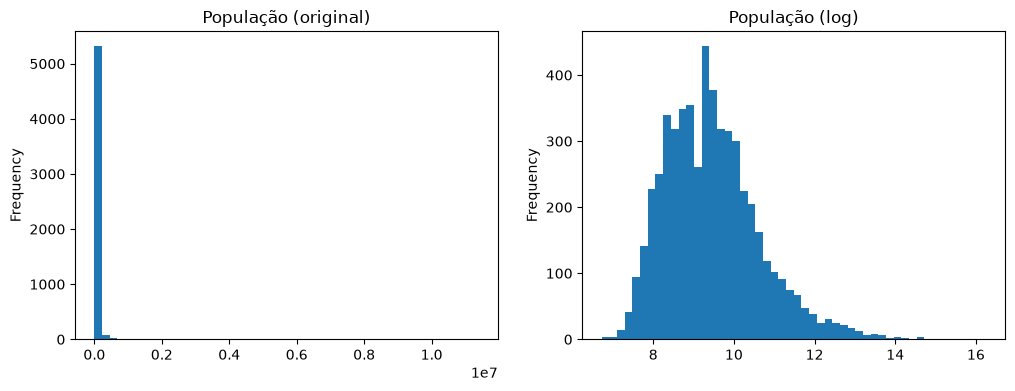

In [40]:
# exemplo visual: população antes e depois do logaritmo
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

municipios["mun_populacao"].plot(kind="hist", bins=50, ax=eixos[0])
eixos[0].set_title("População (original)")

np.log1p(municipios["mun_populacao"]).plot(kind="hist", bins=50, ax=eixos[1])
eixos[1].set_title("População (log)")

plt.show()

In [41]:
# conferência: percentuais acima de 100
colunas_pct = [c for c in NUMERICAS if "_pct_" in c]
(municipios[colunas_pct] > 100).sum()

mun_pct_integral                       0
mun_pct_rural                       1279
mun_pct_transporte                  1105
mun_pct_indigena                       0
mun_pct_quilombola                     0
mun_pct_va_agropecuaria                0
mun_pct_va_industria                   0
mun_pct_va_servicos                    0
mun_pct_va_administracao_publica       0
dtype: int64

**Escolha do tipo de escalonamento**

| Técnica | Como funciona | Avaliação para esta base |
|---|---|---|
| Min-Max | Leva cada coluna para o intervalo de 0 a 1 | Descartada: é muito sensível a valores extremos. Um único município gigante comprime todos os outros perto de 0 |
| **Padronização (z-score)** | Média 0 e desvio padrão 1 | **Escolhida**: é o padrão para a regressão logística do baseline, deixa os coeficientes comparáveis entre si, e o log aplicado antes já reduz os valores extremos das 6 features mais assimétricas |
| Robusta (`RobustScaler`) | Usa a mediana e o intervalo interquartil | Alternativa a testar na etapa de modelagem: é a mais resistente a valores extremos, como os percentuais acima de 100% de `mun_pct_rural` e `mun_pct_transporte` |

**Resultados e decisões:**

- **Transformação logarítmica** (`log1p`) nas features com **assimetria acima de 5** e
  sem valores negativos: população, densidade, total de escolas, percentual indígena,
  percentual quilombola e PIB per capita. O limite de 5 segue um corte natural nos
  dados: depois dessas seis, a maior assimetria cai para cerca de 2,8. O logaritmo
  comprime a cauda longa (por exemplo, São Paulo deixa de ser um ponto isolado mil
  vezes maior que a mediana) e aproxima a distribuição de uma forma simétrica.
- **Padronização** (`StandardScaler`, média 0 e desvio 1) em **todas** as features
  numéricas, depois do logaritmo quando houver, para colocá-las na mesma escala.
- **Ponto de atenção para o grupo:** `mun_pct_rural` e `mun_pct_transporte` têm valores
  acima de 100%, o que é impossível para um percentual: 1.279 municípios (23%) na
  primeira e 1.105 (20%) na segunda, com máximos de 552,6% e 467,0%. A frequência
  indica um erro sistemático no cálculo dessas colunas na Gold, e não valores isolados.
  Para o baseline elas foram mantidas como estão; a correção deve ser discutida com
  quem construiu a Gold, e a interpretação dessas duas features deve ser feita com
  cautela.

In [42]:
# regra da decisão acima, aplicada em código
LIMITE_ASSIMETRIA = 5

NUMERICAS_LOG = [
    c for c in NUMERICAS
    if resumo_dist.loc[c, "assimetria"] > LIMITE_ASSIMETRIA and resumo_dist.loc[c, "minimo"] >= 0
]
NUMERICAS_PADRAO = [c for c in NUMERICAS if c not in NUMERICAS_LOG]

print(f"Com log ({len(NUMERICAS_LOG)}): {NUMERICAS_LOG}")
print(f"Sem log: {len(NUMERICAS_PADRAO)}")

assert sorted(NUMERICAS_LOG + NUMERICAS_PADRAO) == sorted(NUMERICAS)

Com log (6): ['mun_total_escolas', 'mun_populacao', 'mun_densidade', 'mun_pct_indigena', 'mun_pct_quilombola', 'mun_pib_per_capita']
Sem log: 15


## 8. Valores faltantes

Define como preencher os vazios das features. Antes de escolher a técnica, verifica
se os vazios são aleatórios ou se carregam informação.

A imputação é feita **dentro do pipeline** do notebook 03: os valores de preenchimento
(como a mediana) são calculados apenas com os dados de treino, para não vazar
informação do teste.

In [43]:
# features com vazios
nulos_features = (df[FEATURES].isna().mean() * 100).round(3)
nulos_features = nulos_features[nulos_features > 0].sort_values(ascending=False)
print(nulos_features)

# conferência: só numéricas e binárias têm vazios
assert set(nulos_features.index) <= set(NUMERICAS + BINARIAS)

mun_distancia_meta_anterior         2.617
mun_taxa_ano_anterior               0.512
mun_pct_va_agropecuaria             0.006
mun_pct_va_industria                0.006
mun_pct_va_servicos                 0.006
mun_pct_va_administracao_publica    0.006
mun_elegivel_meta                   0.001
dtype: float64


In [44]:
# os vazios da distância da meta coincidem com os municípios não elegíveis?
pd.crosstab(
    df["mun_distancia_meta_anterior"].isna().rename("distancia_vazia"),
    df["mun_elegivel_meta"].astype("string").fillna("vazio"),
)

mun_elegivel_meta,False,True,vazio
distancia_vazia,,,
False,0,1568597,0
True,42139,0,18


In [45]:
# taxa de risco (não alfabetizados) com e sem a distância da meta
y.groupby(df["mun_distancia_meta_anterior"].isna().rename("distancia_vazia")).mean().round(3)

distancia_vazia
False    0.403
True     0.535
Name: nao_alfabetizado, dtype: float64

**Resultados:**

- Os vazios de `mun_distancia_meta_anterior` (2,6% dos alunos) ocorrem **exatamente**
  nos municípios sem meta pactuada: 42.139 alunos de municípios não elegíveis à meta e
  18 alunos com a elegibilidade vazia. Nenhum município elegível tem a distância vazia.
- Os vazios **carregam informação**: a taxa de não alfabetizados é de 53,5% onde a
  distância está vazia, contra 40,3% nos demais. Esse sinal já está representado pela
  feature `mun_elegivel_meta`, que marca os municípios sem meta.

**Decisões de imputação:**

| Features | Estratégia | Motivo |
|---|---|---|
| Numéricas (incluindo `mun_distancia_meta_anterior`, `mun_taxa_ano_anterior` e as `mun_pct_va_*`) | **Mediana** do treino | Robusta a valores extremos, que são comuns nas features municipais (seção 7). A ausência de meta já é sinalizada por `mun_elegivel_meta` |
| `mun_elegivel_meta` | **Constante 0** (não elegível) | Os 18 alunos com elegibilidade vazia também não têm meta, como os não elegíveis. Preencher com o valor mais frequente (elegível) contradiria esse dado |
| Categóricas (`regiao`, `sigla_uf`) | **Valor mais frequente** | Hoje não têm vazios; o passo protege o pipeline contra dados novos incompletos |

**Observação técnica:** `mun_elegivel_meta` tem tipo `object` (verdadeiro, falso e vazio).
No notebook 03 ela será convertida para número (1, 0 e vazio) antes do pipeline, porque o
`SimpleImputer` não aceita valores lógicos com vazios no pandas 3.

## 9. Resumo das decisões

Consolida o papel de cada uma das 35 colunas da Gold e grava as decisões em
`src/config/features_modelo.json`. O notebook `03_modelagem_supervisionada` lê esse
arquivo, de modo que a lista de features e o tratamento de cada uma existem em um
único lugar.

In [46]:
# papel de cada coluna da Gold
papel = {ALVO: "alvo"}
papel.update({c: "identificador" for c in IDENTIFICADORES})
papel[COLUNA_GRUPO] = "identificador (usado na divisão treino/teste)"
papel.update({c: "constante" for c in CONSTANTES})
papel.update({c: "peso amostral" for c in PESO_AMOSTRAL})
papel.update({c: "descartada na seleção" for c in DESCARTADAS_NA_SELECAO})
papel.update({c: "redundante" for c in REDUNDANTES})
papel.update({c: "feature numérica (log + padronização)" for c in NUMERICAS_LOG})
papel.update({c: "feature numérica (padronização)" for c in NUMERICAS_PADRAO})
papel.update({c: "feature categórica (one-hot)" for c in CATEGORICAS})
papel.update({c: "feature binária (0/1)" for c in BINARIAS})

# conferência: todas as 35 colunas classificadas, nenhuma a mais
assert set(papel) == set(df.columns)

resumo = pd.Series(papel, name="papel").rename_axis("coluna")
resumo.value_counts()

papel
feature numérica (padronização)                  15
feature numérica (log + padronização)             6
identificador                                     2
constante                                         2
descartada na seleção                             2
redundante                                        2
feature categórica (one-hot)                      2
alvo                                              1
identificador (usado na divisão treino/teste)     1
peso amostral                                     1
feature binária (0/1)                             1
Name: count, dtype: int64

In [47]:
import json
from pathlib import Path

decisoes = {
    "alvo": ALVO,
    "alvo_invertido": True,          # 1 = não alfabetizado (classe de risco)
    "coluna_grupo": COLUNA_GRUPO,
    "numericas_log": NUMERICAS_LOG,
    "numericas_padrao": NUMERICAS_PADRAO,
    "categoricas": CATEGORICAS,
    "binarias": BINARIAS,
    "imputacao": {                   # nomes no formato do SimpleImputer
        "numericas": "median",
        "categoricas": "most_frequent",
        "binarias_valor": 0,
    },
    "excluidas": {
        "identificadores": IDENTIFICADORES,
        "constantes": CONSTANTES,
        "peso_amostral": PESO_AMOSTRAL,
        "descartadas_na_selecao": DESCARTADAS_NA_SELECAO,
        "redundantes": REDUNDANTES,
    },
}

CAMINHO_DECISOES = Path("../src/config/features_modelo.json")
CAMINHO_DECISOES.write_text(json.dumps(decisoes, indent=2, ensure_ascii=False), encoding="utf-8")

print(f"Gravado em: {CAMINHO_DECISOES.resolve()}")

Gravado em: C:\Users\lfc17\tech-challenge-fase3\src\config\features_modelo.json


In [48]:
# conferência: o arquivo gravado devolve exatamente as mesmas listas
lido = json.loads(CAMINHO_DECISOES.read_text(encoding="utf-8"))
features_lidas = lido["numericas_log"] + lido["numericas_padrao"] + lido["categoricas"] + lido["binarias"]

assert sorted(features_lidas) == sorted(FEATURES)
print(f"Features no arquivo: {len(features_lidas)}")

Features no arquivo: 24


**Síntese:**

- Das 35 colunas da Gold, **24 entram no modelo**: 21 numéricas (6 com transformação
  logarítmica), 2 categóricas (`regiao` e `sigla_uf`) e 1 binária (`mun_elegivel_meta`).
- **11 ficam de fora**: o alvo, 3 identificadores, 2 constantes, o peso amostral,
  2 descartadas na seleção e 2 redundantes. Os motivos estão na tabela da seção 5.
- O alvo é invertido: **1 = não alfabetizado (risco)**. A métrica prioritária é o recall
  dessa classe, acompanhado de precisão e F1.
- A divisão entre treino e teste deve ser feita **por município** (`id_municipio`).

**Pontos em aberto para o grupo:**

1. A taxa mais baixa do RS: erro na origem do dado ou efeito real das enchentes de 2024 (seção 6).
2. `mun_pct_rural` e `mun_pct_transporte` com valores acima de 100% em 20% a 23% dos municípios (seção 7).
3. Uso do `peso_aluno` como peso no treino (`sample_weight`), a decidir no notebook 03.